# Maske kalite seviyeleri ve VQ-VAE tamamlama davranışı

Bu defter iki soruyu inceler:

1. **Kalite seviyelerine ayırma.** Temiz karaciğer maskeleri farklı şiddette bozularak, gerçek Dice'a göre üç kategoriye ayrılır: **iyi (Dice > 0.7)**, **orta (0.5 - 0.7)** ve **kötü (< 0.5)**. Kötü ve orta seviyeye ulaşmak için ağır erozyon ve kısmi/merkez bozulmaları kullanılır.
2. **VQ-VAE bozuk maskeyi tamamlıyor mu?** Her bozuk girdi VQ-VAE ile yeniden üretilir. Ölçülen anahtar büyüklük: `Dice(rekonstrüksiyon, temiz GT)` ile `Dice(girdi, temiz GT)` farkı. Rekonstrüksiyonun GT'ye yakınlığı girdininkinden büyükse, model bozuk maskeyi öğrendiği şekil manifolduna doğru **düzeltiyor** (tamamlıyor) demektir.

Ağır bozulma primitifleri: **ağır erozyon** (Dice'ı 0.5 altına indirir), **merkez-only** (yalnız organın merkez çekirdeği bırakılır) ve **kısmi** (maskenin bir parçası kesilir). Rekonstrüksiyon için standart VQ-VAE ve SimVQ kullanılır.

In [8]:
import sys, logging
from pathlib import Path

import numpy as np
import torch
%matplotlib inline
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.WARNING)

def find_root(start):
    p = Path(start).resolve()
    for c in [p, *p.parents]:
        if (c / 'scripts').is_dir() and (c / 'models').is_dir():
            return c
    return p

PROJECT_ROOT = find_root(Path.cwd())
for p in (PROJECT_ROOT, PROJECT_ROOT / 'scripts'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print('PROJECT_ROOT =', PROJECT_ROOT)

from data import load_config
from data.degradations import SyntheticDegrader, dice
from data.degradations_3d import PRIMITIVES_3D
from data.degradations_partial_3d import PARTIAL_PRIMITIVES_3D, heavy_erode, center_only, partial
from models.vae3d_vq import ConvVQVAE3D
from train import resolve_device, set_seed
import evaluate_correlation_3d as ev3d
import evaluate_correlation_3d_simvq as ev3dsimvq

device = resolve_device('auto')
print('device =', device)

PROJECT_ROOT = C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality
device = cuda


## 1. Temiz test maskeleri

Test bölünmesindeki temiz karaciğer maskeleri yüklenir (kareye sıkıştırılmış 64³ uzayda; değerlendirme boyunca tek koordinat çerçevesi korunur).

In [9]:
SEED = 42
config = load_config(str(PROJECT_ROOT / 'configs' / 'vae3d_vq.yaml'))
config.setdefault('data', {})['data_source'] = 'precomputed'
set_seed(SEED)

clean_masks = ev3d.load_clean_volumes(config, 'test', None, SEED)
clean_masks = [m.astype(bool) for m in clean_masks]
print(f'temiz test maskesi: {len(clean_masks)}')

temiz test maskesi: 47


## 2. Kalite seviyelerine ayrılmış bozuk küme

Her temiz maskeden farklı hedef Dice'larda bozuk varyantlar üretilir. Standart 3B primitiflere ek olarak ağır erozyon / merkez-only / kısmi primitifleri de degrader'a verilir; böylece severity araması düşük Dice hedeflerine (kötü kategori) ulaşabilir. Her bozuk örnek için kaynağı olan temiz maskenin indeksi saklanır (tamamlama ölçümü bunu gerektirir).

In [10]:
# Standart + ağır primitifleri birleştir; degrader severity aramasıyla hedefe kilitlenir.
ALL_PRIMS = {**PRIMITIVES_3D, **PARTIAL_PRIMITIVES_3D}
degrader = SyntheticDegrader.from_config(config, primitives=ALL_PRIMS)
degrader.calibrate(clean_masks)   # ulaşılabilir Dice aralıklarını gerçek maskelerde ölç

# Tüm kovaları (iyi/orta/kötü) doldurmak için hedef Dice spektrumu
TARGETS = [0.90, 0.80, 0.65, 0.55, 0.40, 0.28]
rng = np.random.default_rng(SEED)

deg_masks, deg_dice, deg_ref = [], [], []   # bozuk maske, Dice(girdi,GT), temiz indeks
for ci, m in enumerate(clean_masks):
    for t in TARGETS:
        dmask, td = degrader.make_pair(m, rng, target_dice=float(t))
        deg_masks.append(np.asarray(dmask) > 0)
        deg_dice.append(float(td))
        deg_ref.append(ci)

deg_masks = np.stack(deg_masks)
deg_dice = np.asarray(deg_dice)
deg_ref = np.asarray(deg_ref)

def bucket(d):
    if d > 0.7: return 'iyi'
    if d >= 0.5: return 'orta'
    return 'kötü'

buckets = np.array([bucket(d) for d in deg_dice])
for b in ['iyi', 'orta', 'kötü']:
    n = int((buckets == b).sum())
    sub = deg_dice[buckets == b]
    rng_txt = f'[{sub.min():.2f}, {sub.max():.2f}]' if n else '-'
    print(f'{b:5s}: {n:4d} örnek   Dice {rng_txt}')

iyi  :   98 örnek   Dice [0.72, 0.93]
orta :  110 örnek   Dice [0.50, 0.67]
kötü :   74 örnek   Dice [0.36, 0.50]


## 3. VQ-VAE modellerini yükle

Rekonstrüksiyon standart VQ-VAE ve SimVQ ile yapılır. İkisi de bozuk girdiyi `reconstruct` ile ikili maskeye çevirir.

In [11]:
CKPT = PROJECT_ROOT / 'outputs' / 'checkpoints'

def load_vq(path):
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    v = ckpt['config']['vae3d_vq']
    m = ConvVQVAE3D(
        base_channels=int(v['base_channels']), num_embeddings=int(v['num_embeddings']),
        embedding_dim=int(v['embedding_dim']), commitment_cost=float(v['commitment_cost']),
        input_size=tuple(v['input_size']), use_skip=bool(v.get('use_skip', False)),
        vq_mode=str(v.get('vq_mode', 'standard')))
    m.load_state_dict(ckpt['model_state']); m.to(device).eval(); return m

MODELS = {}
vq_path = CKPT / 'vae3d_vqvae_best.pt'
simvq_path = CKPT / 'vae3d_simvq_best.pt'
if vq_path.exists():
    MODELS['standart VQ'] = load_vq(vq_path)
if simvq_path.exists():
    MODELS['SimVQ'] = ev3dsimvq.load_simvq_model(simvq_path, device)
print('yüklenen modeller:', list(MODELS))

@torch.no_grad()
def reconstruct_batch(model, masks_np, batch=32):
    outs = []
    for s in range(0, len(masks_np), batch):
        x = torch.from_numpy(masks_np[s:s+batch].astype('float32'))[:, None].to(device)
        rec = model.reconstruct(x)[:, 0].cpu().numpy() > 0.5
        outs.append(rec)
    return np.concatenate(outs)

yüklenen modeller: ['standart VQ', 'SimVQ']


## 4. Tamamlama ölçümü: rekonstrüksiyon bozuğu düzeltiyor mu?

Her bozuk girdi için `Dice(girdi, temiz GT)` (zaten biliniyor) ile `Dice(rekonstrüksiyon, temiz GT)` karşılaştırılır. Fark pozitifse model girdiyi doğru şekle **çekmiş** (tamamlamış) demektir. Kova bazında ortalamalar, modelin hangi bozulma seviyesinde ne kadar düzeltme yaptığını gösterir.

In [12]:
rows = []
recon_dice_to_gt = {}   # model -> array: Dice(recon, temiz GT)
for mname, model in MODELS.items():
    recs = reconstruct_batch(model, deg_masks)
    rdice = np.array([dice(clean_masks[deg_ref[i]], recs[i]) for i in range(len(recs))])
    recon_dice_to_gt[mname] = rdice
    for b in ['iyi', 'orta', 'kötü']:
        sel = buckets == b
        if not sel.any():
            continue
        din = deg_dice[sel].mean()
        drec = rdice[sel].mean()
        rows.append({
            'model': mname, 'kategori': b, 'n': int(sel.sum()),
            'Dice girdi→GT': round(float(din), 3),
            'Dice recon→GT': round(float(drec), 3),
            'iyileşme': round(float(drec - din), 3),
        })

try:
    import pandas as pd
    completion_df = pd.DataFrame(rows)
    display(completion_df)
except Exception:
    for r in rows:
        print(r)

,model,kategori,n,Dice girdi→GT,Dice recon→GT,iyileşme
0,standart VQ,iyi,98,0.848,0.822,-0.027
1,standart VQ,orta,110,0.588,0.621,0.033
2,standart VQ,kötü,74,0.415,0.467,0.052
3,SimVQ,iyi,98,0.848,0.825,-0.024
4,SimVQ,orta,110,0.588,0.598,0.010
5,SimVQ,kötü,74,0.415,0.442,0.026


## 5. Zorlu vakalar: ağır erozyon, merkez-only, kısmi maske

Hocanın örneklerine doğrudan yanıt: tek bir temiz maske üç şekilde ağır bozulur (ağır erozyon ~0.5 Dice, yalnız merkez bölge, yalnız bir parça) ve her modelin bu girdiyi tamamlayıp tamamlayamadığı orta eksenel kesitte gösterilir. Başlıklarda `Dice(girdi→GT)` ve `Dice(recon→GT)` verilir.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\maske_kalite_zorlu_vakalar.png


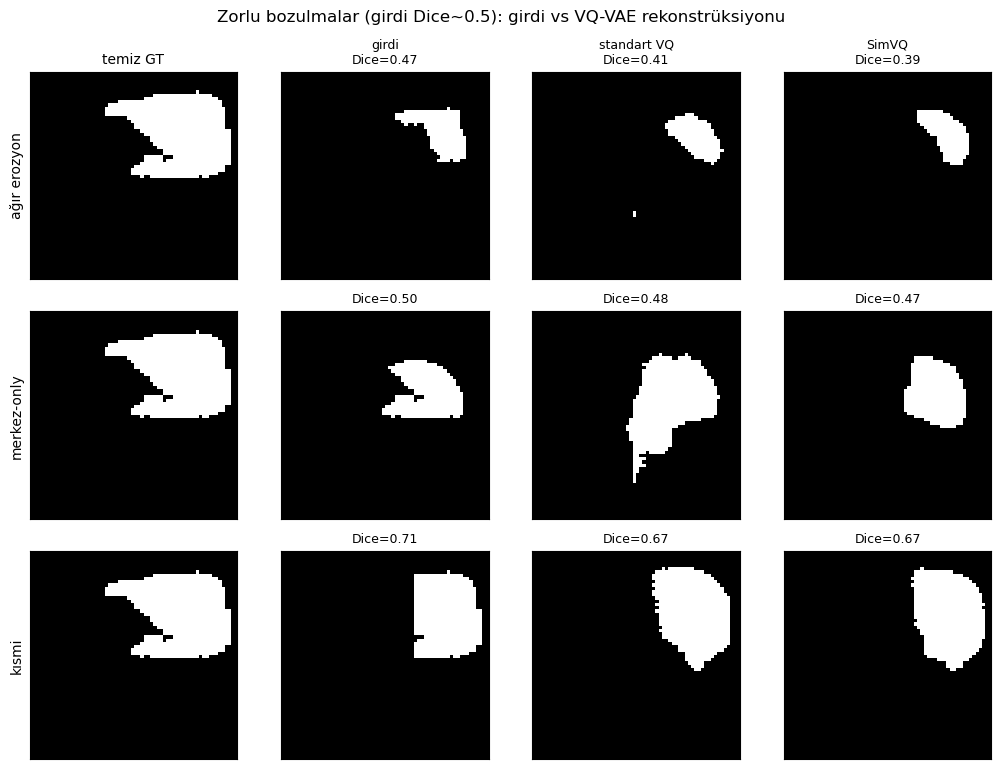

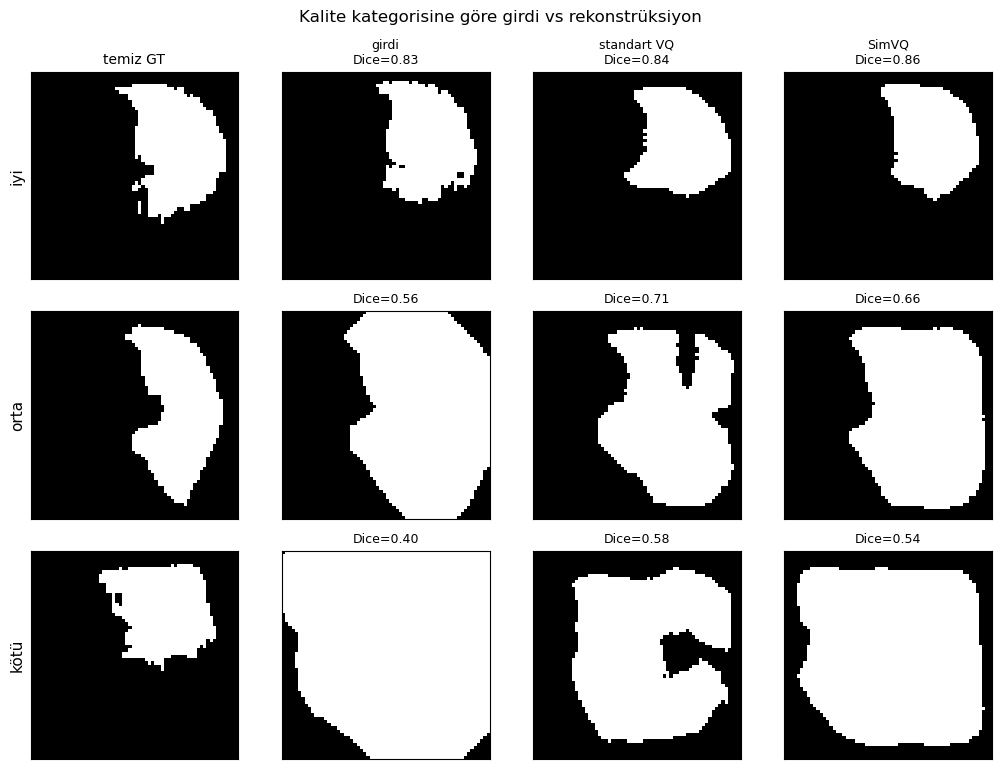

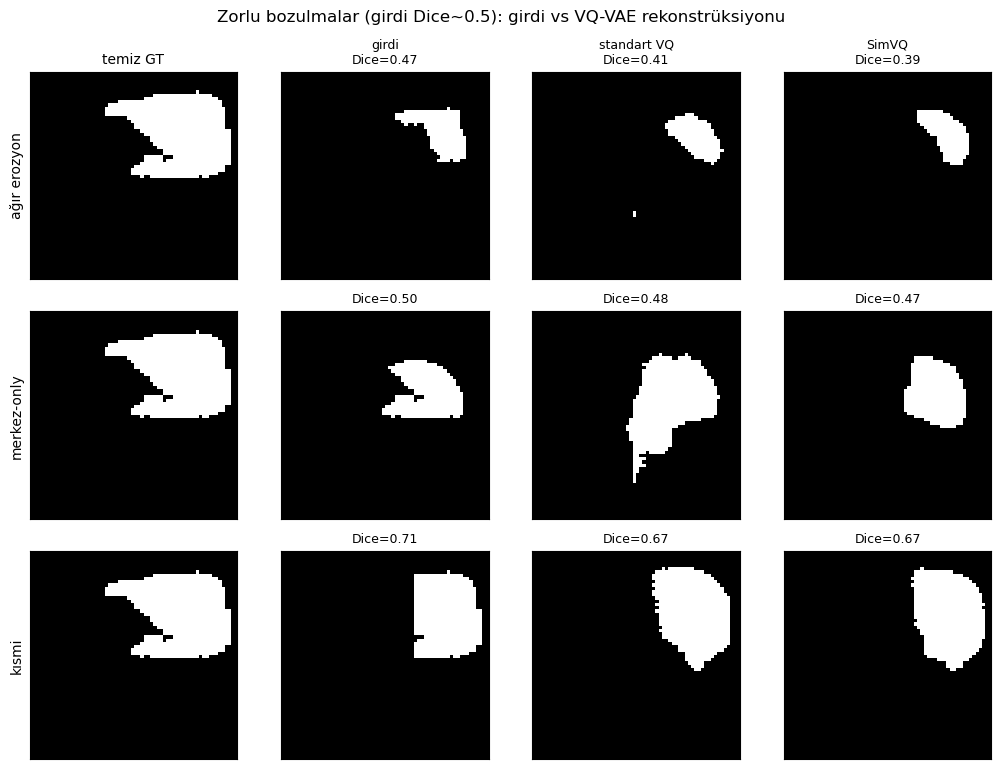

In [13]:
# Orta boy bir temiz maske seç (çok büyük maske ağır erozyonda tamamen kaybolur)
areas = np.array([m.sum() for m in clean_masks])
ci = int(np.argsort(areas)[len(areas) // 2])   # medyan büyüklük
gt = clean_masks[ci]

def to_target(fn, target=0.5, iters=14):
    """severity'i ikili aramayla Dice(girdi,GT)~target olacak şekilde çöz."""
    lo, hi, best = 0.0, 1.0, None
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        out = fn(gt.astype('float32'), mid, np.random.default_rng(0)) > 0
        d = dice(gt, out)
        if best is None or abs(d - target) < abs(best[1] - target):
            best = (out, d)
        if d > target: lo = mid       # az bozulma -> severity artır
        else: hi = mid
    return best[0]

cases = {
    'ağır erozyon': to_target(heavy_erode, 0.5),
    'merkez-only': to_target(center_only, 0.5),
    'kısmi': to_target(partial, 0.5),
}

model_names = list(MODELS)
ncol = 2 + len(model_names)   # GT | girdi | her model
fig, axes = plt.subplots(len(cases), ncol, figsize=(2.6*ncol, 2.6*len(cases)))
axes = np.atleast_2d(axes)
zc = gt.shape[0] // 2
for ri, (cname, cin) in enumerate(cases.items()):
    din = dice(gt, cin)
    axes[ri, 0].imshow(gt[zc], cmap='gray')
    axes[ri, 0].set_ylabel(cname, fontsize=10)
    if ri == 0: axes[ri, 0].set_title('temiz GT', fontsize=10)
    axes[ri, 1].imshow(cin[zc], cmap='gray')
    axes[ri, 1].set_title(f'girdi\nDice={din:.2f}' if ri == 0 else f'Dice={din:.2f}', fontsize=9)
    for k, mname in enumerate(model_names):
        rec = reconstruct_batch(MODELS[mname], cin[None])[0]
        drec = dice(gt, rec)
        axes[ri, 2+k].imshow(rec[zc], cmap='gray')
        ttl = (mname + '\n' if ri == 0 else '') + f'Dice={drec:.2f}'
        axes[ri, 2+k].set_title(ttl, fontsize=9)
    for c in range(ncol):
        axes[ri, c].set_xticks([]); axes[ri, c].set_yticks([])
fig.suptitle('Zorlu bozulmalar (girdi Dice~0.5): girdi vs VQ-VAE rekonstrüksiyonu', fontsize=12)
fig.tight_layout()
out1 = PROJECT_ROOT / 'outputs' / 'maske_kalite_zorlu_vakalar.png'
fig.savefig(out1, dpi=150, bbox_inches='tight')
print('kaydedildi:', out1)
plt.show()

## 6. Kova başına örnek görseller

Her kalite kategorisinden (iyi / orta / kötü) birer örnek: temiz GT, bozuk girdi ve her modelin rekonstrüksiyonu yan yana. Kova bazında modelin düzeltme davranışının görsel karşılığı.

kaydedildi: C:\Users\ahmet.yaylalioglu\Desktop\phd_studies_anatomy\projects\segquality\outputs\maske_kalite_kovalar.png


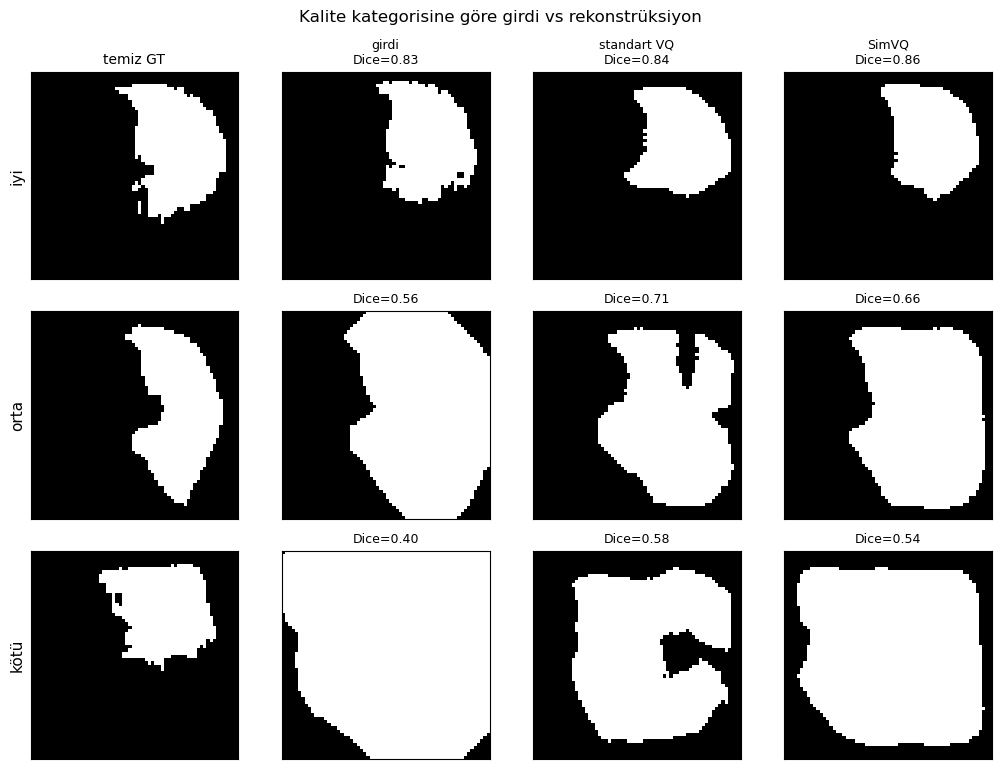

In [14]:
# her kovadan bir örnek indeks
example_idx = {}
for b in ['iyi', 'orta', 'kötü']:
    ids = np.where(buckets == b)[0]
    if len(ids):
        # kova ortasına yakın bir örnek
        example_idx[b] = int(ids[np.argsort(np.abs(deg_dice[ids] - np.median(deg_dice[ids])))[0]])

model_names = list(MODELS)
ncol = 2 + len(model_names)
rows_b = list(example_idx)
fig, axes = plt.subplots(len(rows_b), ncol, figsize=(2.6*ncol, 2.6*len(rows_b)))
axes = np.atleast_2d(axes)
for ri, b in enumerate(rows_b):
    i = example_idx[b]
    gt = clean_masks[deg_ref[i]]
    cin = deg_masks[i]
    zc = gt.shape[0] // 2
    axes[ri, 0].imshow(gt[zc], cmap='gray'); axes[ri, 0].set_ylabel(b, fontsize=11)
    if ri == 0: axes[ri, 0].set_title('temiz GT', fontsize=10)
    axes[ri, 1].imshow(cin[zc], cmap='gray')
    axes[ri, 1].set_title(f'girdi\nDice={deg_dice[i]:.2f}' if ri == 0 else f'Dice={deg_dice[i]:.2f}', fontsize=9)
    for k, mname in enumerate(model_names):
        drec = recon_dice_to_gt[mname][i]
        rec = reconstruct_batch(MODELS[mname], cin[None])[0]
        axes[ri, 2+k].imshow(rec[zc], cmap='gray')
        ttl = (mname + '\n' if ri == 0 else '') + f'Dice={drec:.2f}'
        axes[ri, 2+k].set_title(ttl, fontsize=9)
    for c in range(ncol):
        axes[ri, c].set_xticks([]); axes[ri, c].set_yticks([])
fig.suptitle('Kalite kategorisine göre girdi vs rekonstrüksiyon', fontsize=12)
fig.tight_layout()
out2 = PROJECT_ROOT / 'outputs' / 'maske_kalite_kovalar.png'
fig.savefig(out2, dpi=150, bbox_inches='tight')
print('kaydedildi:', out2)
plt.show()

## 7. Bulguların özeti

- **Kalite seviyeleri.** Ağır erozyon / merkez-only / kısmi primitifleri, standart setin ulaşamadığı düşük Dice bölgesini doldurur; böylece iyi (>0.7), orta (0.5-0.7) ve kötü (<0.5) kovaları örneklenir (Dice > 0.7 = iyi eşiği).
- **Tamamlama.** Kova tablosundaki `iyileşme = Dice(recon→GT) − Dice(girdi→GT)` sütunu modelin düzeltme gücünü ölçer. Pozitif iyileşme, VQ-VAE'nin bozuk girdiyi öğrendiği şekil manifolduna çektiğini (tamamladığını) gösterir; bozulma arttıkça (kötü kova) modelin ne kadar bilgi tamamlayabildiği net görülür.
- **Zorlu vakalar.** Yalnız merkez veya yalnız bir parça verildiğinde rekonstrüksiyonun tam organa ne kadar yaklaştığı, modelin şekil önceliğini (prior) ne ölçüde kullandığını doğrudan gösterir.

Üretilen dosyalar: `outputs/maske_kalite_zorlu_vakalar.png`, `outputs/maske_kalite_kovalar.png`.